# Segundo Parcial: Regresión Logística

**Universidad:** Universidad Autónoma Tomás Frías (UATF), Ingeniería Informática

**Materia:** INF-672 Machine Learning

**Docente:** Dr. Huascar Fedor Gonzale

**Estudiante:** Erasmo Flores Salvador 

**Fecha de entrega:** 11 de noviembre de 2026

In [1]:
import warnings
import re
import string
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import nltk
from bs4 import BeautifulSoup, MarkupResemblesLocatorWarning
from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize
from nltk.stem import PorterStemmer
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, ConfusionMatrixDisplay

warnings.filterwarnings("ignore", category=MarkupResemblesLocatorWarning)
nltk.download('punkt', quiet=True)
nltk.download('punkt_tab', quiet=True)
nltk.download('stopwords', quiet=True)

True

In [2]:
df = pd.read_csv('IMDB Dataset.csv')
print(df.shape)
df.head()

(50000, 2)


,review,sentiment
0,One of the other reviewers has mentioned that ...,positive
1,A wonderful little production. <br /><br />The...,positive
2,I thought this was a wonderful way to spend ti...,positive
3,Basically there's a family where a little boy ...,negative
4,"Petter Mattei's ""Love in the Time of Money"" is...",positive


## Carga y exploración

### Descripción del conjunto de datos

Leí el archivo IMDB Dataset.csv con pandas. El dataset tiene 50 000 filas y 2 columnas. La columna review guarda el texto completo de la reseña, escrita en inglés por un usuario, y a veces trae etiquetas HTML como <br />. La columna sentiment guarda la etiqueta de la reseña, que puede ser positive o negative. Es decir que cada fila es una reseña con su clase, y el objetivo es que el modelo aprenda a predecir sentiment a partir del texto de review.

In [3]:
print(df['sentiment'].value_counts())
print(df.isnull().sum())
print(df.duplicated().sum())

sentiment
positive    25000
negative    25000
Name: count, dtype: int64
review       0
sentiment    0
dtype: int64
418


In [4]:
df = df.drop_duplicates().reset_index(drop=True)
print(df.shape)
print(df['sentiment'].value_counts())

(49582, 2)
sentiment
positive    24884
negative    24698
Name: count, dtype: int64


### Distribución de clases, nulos y duplicados

Al inicio las dos clases están perfectamente balanceadas, con 25 000 reseñas positivas y 25 000 negativas. No hay valores nulos en ninguna de las dos columnas.

Sí encontré 418 reseñas duplicadas, es decir, filas con el mismo texto y la misma etiqueta. Decidí eliminarlas porque si un mismo texto queda en entrenamiento y también en prueba, el modelo ya lo habría visto y el resultado saldría más alto de lo real. Después de eliminarlas quedan 49 582 reseñas, 24 884 positivas y 24 698 negativas, o sea que las clases siguen casi balanceadas y no hace falta hacer nada más.

             count        mean         std   min    25%    50%    75%     max
sentiment                                                                    
negative   24698.0  229.596607  165.103430   4.0  128.0  174.0  278.0  1522.0
positive   24884.0  233.090620  177.688169  10.0  125.0  172.0  284.0  2470.0


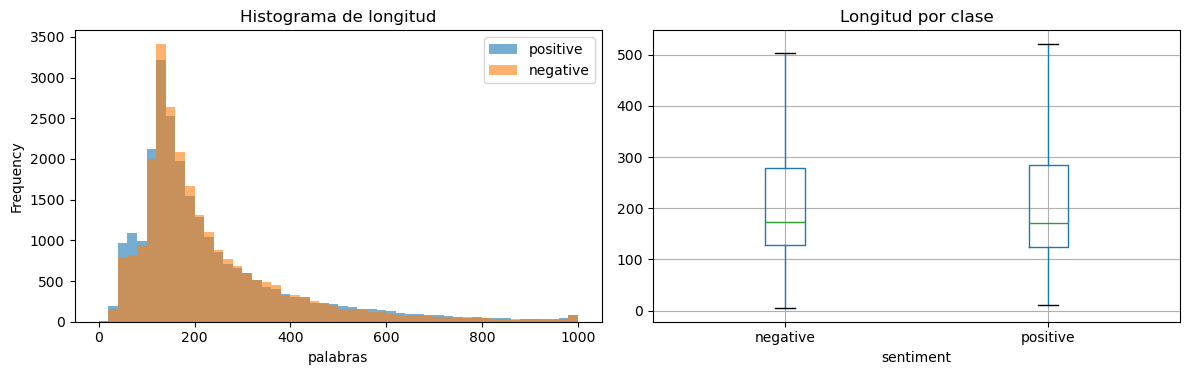

In [5]:
df['longitud'] = df['review'].str.split().str.len()
print(df.groupby('sentiment')['longitud'].describe())

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
df[df['sentiment'] == 'positive']['longitud'].plot.hist(bins=50, alpha=0.6, ax=ax[0], label='positive', range=(0, 1000))
df[df['sentiment'] == 'negative']['longitud'].plot.hist(bins=50, alpha=0.6, ax=ax[0], label='negative', range=(0, 1000))
ax[0].set_title('Histograma de longitud')
ax[0].set_xlabel('palabras')
ax[0].legend()
df.boxplot(column='longitud', by='sentiment', ax=ax[1], showfliers=False)
ax[1].set_title('Longitud por clase')
plt.suptitle('')
plt.tight_layout()
plt.show()

### Longitud de las reseñas

Calculé la longitud de cada reseña contando sus palabras y comparé las dos clases con un histograma y un diagrama de cajas. Las reseñas negativas tienen en promedio 229 palabras y las positivas 233. Las medianas también son casi iguales (174 y 172). Hay reseñas muy cortas (de 4 y 10 palabras) y otras muy largas (hasta 1 522 en las negativas y 2 470 en las positivas).

En los gráficos se ve que las dos clases tienen una distribución casi igual: muchas reseñas cortas o medianas y pocas muy largas. Entonces la longitud no sirve para distinguir una reseña positiva de una negativa, y el modelo tendrá que fijarse en las palabras que se usan.

## In [2] Preprocesamiento del texto
Punto 1: inspeccionar reseñas e identificar lo “sucio”

In [6]:
for texto in df['review'].sample(3, random_state=1).values:
    print(texto[:400])
    print()

I saw this show about 3-4 years ago. It was dam Funny! When i first time i saw it was playing on ETV(Estonian Television) And i started to like it. Too bad that that show is on bad time for me. Hyde is like a cool guy who likes to sing Frank Sinatra! And he comes on stupid ideas. He got these glasses which h are brown. I like it . And there's FeZ. The group Pervert. We all know what he does when h

Of the spate of Austen films from the 1990s, this is my favorite, more even than "Persuasion," which was the one that converted me to Austeniana. Before seeing this "Emma" I had seen two previous versions, but in one Emma seemed all wrong, more like Lady Teazle, and in the other she seemed half wrong, like a possible impostor, whereas here she seemed just right, young and silly and stubborn. In ge

The producer, Matt Mochary, stumbled upon the film's subject, Anderson Sa (leader of the AfroReggae music movement), when on a Hewlett Foundation trip to Rio de Janeiro. Mochary was so moved by Sa

In [38]:
patrones = {
    'etiqueta br': r'<br\s*/?>',
    'otras etiquetas html': r'<(?!br)[^>]+>',
    'urls con http': r'https?://\S+',
    'urls con www': r'www\.\S+',
    'prefijo (Reuters) o (AP)': r'\((?:Reuters|AP)\)',
    'numeros': r'\d',
    'mayusculas': r'[A-Z]',
    'signos de puntuacion': r'[^\w\s]',
    'caracteres no ascii': r'[^\x00-\x7f]'
}
for nombre, patron in patrones.items():
    print(nombre, df['review'].str.contains(patron, regex=True).sum())

etiqueta br 28966
otras etiquetas html 25
urls con http 119
urls con www 138
prefijo (Reuters) o (AP) 0
numeros 27786
mayusculas 49364
signos de puntuacion 49578
caracteres no ascii 4624


In [8]:
for patron in [r'https?://\S+', r'www\.\S+', r'<(?!br)[^>]+>']:
    texto = df['review'][df['review'].str.contains(patron, regex=True)].iloc[0]
    m = re.search(patron, texto)
    print(texto[max(0, m.start() - 60):m.end() + 60])
    print()

 pages of film.<br /><br />- A review by Jamie Robert Ward (http://www.invocus.net)

EPTIC'S GUIDE TO AN INCONVENIENT TRUTH" can be found at is :www.cei.org. A shorter 10-page version can be found at: www.cei.org/pdf/

her you should slap him or bring him home (and NOT to Mom!).<p><br /><br />There are other stand-out performances as well. 



In [9]:
def strip_html(text):
    return BeautifulSoup(text, "html.parser").get_text(" ")

def remove_urls(text):
    return re.sub(r'https?://\S+|www\.\S+', '', text)

def remove_punctuation(text):
    text = text.lower()
    text = text.replace("'", "")
    text = text.translate(str.maketrans(string.punctuation, ' ' * len(string.punctuation)))
    text = re.sub(r'[\u2018\u2019\u201C\u201D\u2013\u2014\u2026]', ' ', text)
    return text

print(strip_html("Great film.<br /><br />Loved it"))
print(remove_urls("Visit www.cei.org or http://www.invocus.net now"))
print(remove_punctuation("I don't like it, it wasn't good!"))


Great film. Loved it
Visit  or  now
i dont like it  it wasnt good 


Revisé varias reseñas y vi que casi todas traen la etiqueta <br /> (28 966 reseñas). También encontré otras etiquetas HTML como <p> en 25 reseñas, y enlaces en unas 250 (119 con http y 138 que empiezan con www). Además hay números, mayúsculas, signos de puntuación y 4 624 reseñas con caracteres raros que no son ASCII.

Adapté las funciones de clase solo a lo que sí existe. Eliminé el HTML con BeautifulSoup, usando get_text con un espacio para que las palabras no se peguen cuando se borra un <br />. Eliminé las URLs con una expresión regular que, además de http, cubre los enlaces con www, que en clase no estaban. Pasé todo a minúsculas y quité la puntuación cambiándola por espacios, pero borrando el apóstrofo para que "didn't" quede como "didnt".

El paso de clase que quitaba un prefijo tipo "(Reuters) -" no lo usé, porque en este dataset no hay ninguna reseña con (Reuters) ni (AP). Los números tampoco los eliminé, porque aparecen en puntajes como "8/10" o "1/10", y eso ayuda a saber si la reseña es buena o mala.
## Punto 2: stopwords (not, no, but)

In [10]:
stop_todas = set(stopwords.words('english'))
print(len(stop_todas))
print([p for p in ['not', 'no', 'nor', 'but', 'very', 'too', 'against'] if p in stop_todas])

stop_menos = stop_todas - {'not', 'no', 'nor', 'but', 'very', 'too', 'against'}
stemmer = PorterStemmer()

198
['not', 'no', 'nor', 'but', 'very', 'too', 'against']


In [11]:
def preprocesar_texto(text, stop):
    text = strip_html(text)
    text = remove_urls(text)
    text = remove_punctuation(text)
    tokens = word_tokenize(text)
    tokens = [t for t in tokens if t not in stop]
    tokens = [stemmer.stem(t) for t in tokens]
    return " ".join(tokens)

ejemplo = "I didn't like it. Not good, but the acting was very bad!<br /><br />1/10"
print(preprocesar_texto(ejemplo, stop_todas))
print(preprocesar_texto(ejemplo, stop_menos))

didnt like good act bad 1 10
didnt like not good but act veri bad 1 10


## Punto 3: muestra de 5 000 reseñas

In [13]:
muestra = df.sample(5000, random_state=42).reset_index(drop=True)
muestra['limpio_todas'] = muestra['review'].apply(lambda t: preprocesar_texto(t, stop_todas))
muestra['limpio_menos'] = muestra['review'].apply(lambda t: preprocesar_texto(t, stop_menos))
y = muestra['sentiment']

print(muestra['review'][0][:200])
print(muestra['limpio_todas'][0][:200])
print(muestra['limpio_menos'][0][:200])

"Soul Plane" is a horrible attempt at comedy that only should appeal people with thick skulls, bloodshot eyes and furry pawns. <br /><br />The plot is not only incoherent but also non-existent, acting
soul plane horribl attempt comedi appeal peopl thick skull bloodshot eye furri pawn plot incoher also non exist act mostli sub sub par gang highli moron dread charact thrown bad measur joke often spot
soul plane horribl attempt comedi appeal peopl thick skull bloodshot eye furri pawn plot not incoher but also non exist act mostli sub sub par gang highli moron dread charact thrown bad measur joke of


In [14]:
for palabra in ['not', 'no', 'nor', 'but', 'very', 'too', 'against']:
    raiz = stemmer.stem(palabra)
    aparece = muestra['limpio_menos'].str.split().apply(lambda t: raiz in t)
    en_neg = aparece[muestra['sentiment'] == 'negative'].mean() * 100
    en_pos = aparece[muestra['sentiment'] == 'positive'].mean() * 100
    print(palabra, round(en_neg, 1), round(en_pos, 1))

not 62.9 57.6
no 38.0 27.4
nor 2.7 1.6
but 73.7 72.1
very 30.1 39.6
too 23.6 21.8
against 4.4 5.7


In [15]:
for frase in ['not good', 'not bad', 'not great']:
    neg = muestra['limpio_menos'][muestra['sentiment'] == 'negative'].str.contains(frase).sum()
    pos = muestra['limpio_menos'][muestra['sentiment'] == 'positive'].str.contains(frase).sum()
    print(frase, neg, pos)

not good 82 34
not bad 57 35
not great 15 34


In [16]:
def probar(columna, vectorizador):
    X_tr, X_te, y_tr, y_te = train_test_split(muestra[columna], y, test_size=0.2, stratify=y, random_state=42)
    a = vectorizador.fit_transform(X_tr)
    b = vectorizador.transform(X_te)
    modelo = LogisticRegression(max_iter=1000).fit(a, y_tr)
    pred = modelo.predict(b)
    return round(accuracy_score(y_te, pred), 4), round(f1_score(y_te, pred, pos_label='positive'), 4)

print('BoW quitando todas las stopwords', probar('limpio_todas', CountVectorizer()))
print('BoW conservando negaciones', probar('limpio_menos', CountVectorizer()))
print('TF-IDF quitando todas las stopwords', probar('limpio_todas', TfidfVectorizer()))
print('TF-IDF conservando negaciones', probar('limpio_menos', TfidfVectorizer()))

BoW quitando todas las stopwords (0.835, 0.8387)
BoW conservando negaciones (0.843, 0.8465)
TF-IDF quitando todas las stopwords (0.844, 0.85)
TF-IDF conservando negaciones (0.848, 0.8524)


#### Punto 2: decisión sobre las stopwords
La lista de stopwords de NLTK tiene 198 palabras e incluye not, no, nor, but, very, too y against. Eliminarlas sí afecta a un problema de sentimiento, porque "not good" y "good" significan lo contrario. En el ejemplo se ve claro: quitando todas las stopwords la frase queda "didnt like good act bad", y conservando las negaciones queda "didnt like not good but act veri bad". Con la primera versión se pierde el "not". Las contracciones como "didn't" no se pierden, porque al borrar el apóstrofo quedan como "didnt", que no está en la lista.

Los datos de la muestra lo confirman. La palabra "not" aparece en el 62.9 % de las reseñas negativas y en el 57.6 % de las positivas, y "no" aparece en el 38.0 % de las negativas contra el 27.4 % de las positivas. Lo contrario pasa con "very" (aparece como "veri" por el stemming), que está en el 39.6 % de las positivas y en el 30.1 % de las negativas. La palabra "but" aparece casi igual en las dos clases (73.7 % y 72.1 %), así que aporta poco por sí sola, pero tampoco molesta. También se ve que las frases cambian de sentido: "not good" aparece 82 veces en reseñas negativas y 34 en positivas, y "not great" aparece 15 veces en negativas y 34 en positivas, algo que el modelo no podría distinguir si borrara el "not".

Para comprobarlo con el modelo, probé las dos opciones. Con Bag of Words, quitar todas las stopwords dio 0.835 de exactitud y 0.8387 de F1, y conservar las negaciones dio 0.843 y 0.8465. Con TF-IDF dio 0.844 y 0.85 contra 0.848 y 0.8524. En los dos casos mejora un poco conservándolas.
Mi decisión es conservar esas siete palabras y quitar el resto de las stopwords, porque cambian el significado de la frase, aparecen distinto en cada clase y mejoran los resultados.

#### Punto 3: muestra de trabajo
Trabajé primero con una muestra de 5 000 reseñas, tomada al azar con random_state=42 para poder repetir el resultado. Como el dataset es grande, así el procesamiento es rápido. Al final escalo al dataset completo para ver si los resultados se mantienen.

### Escalar al dataset completo

Como mi equipo lo permitió, apliqué el mismo preprocesamiento a las 49 582 reseñas, conservando las negaciones. Esta columna limpia la uso al final para comparar los modelos con todos los datos.
## In [3] División de los datos
Punto 1: separar en 80 % entrenamiento y 20 % prueba

In [22]:
X_train, X_test, y_train, y_test = train_test_split(muestra['limpio_menos'], y, test_size=0.2, stratify=y, random_state=42)
print(X_train.shape, X_test.shape)
print(y_train.value_counts())
print(y_test.value_counts())

(4000,) (1000,)
sentiment
negative    2008
positive    1992
Name: count, dtype: int64
sentiment
negative    502
positive    498
Name: count, dtype: int64


### In [3] División de los datos

Separé la muestra de 5 000 reseñas en 80 % para entrenamiento (4 000 reseñas) y 20 % para prueba (1 000 reseñas), con train_test_split, usando stratify=y y random_state=42. Usé la columna limpia (la que conserva las negaciones) como entrada, y la columna sentiment como etiqueta.

Con stratify se mantiene el balance de las clases: en entrenamiento hay 2 008 reseñas negativas y 1 992 positivas, y en prueba hay 502 negativas y 498 positivas. Con random_state=42 la división siempre sale igual, así que los resultados se pueden repetir.

In [23]:
vec_train = CountVectorizer().fit(X_train)
vec_todo = CountVectorizer().fit(muestra['limpio_menos'])

print('palabras aprendidas solo con entrenamiento:', len(vec_train.vocabulary_))
print('palabras aprendidas con todos los datos:', len(vec_todo.vocabulary_))
print('palabras que solo vienen de prueba:', len(vec_todo.vocabulary_) - len(vec_train.vocabulary_))

palabras aprendidas solo con entrenamiento: 24332
palabras aprendidas con todos los datos: 26922
palabras que solo vienen de prueba: 2590


#### ¿Por qué el vectorizador se ajusta (fit) solo con los datos de entrenamiento?

Cuando el vectorizador hace fit, aprende el vocabulario y, en el caso de TF-IDF, también qué tan comunes son las palabras. Si lo ajustara con todos los datos, estaría usando información de las reseñas de prueba antes de evaluar el modelo. Eso se llama fuga de datos (data leakage), y haría que el resultado saliera mejor de lo que es en realidad.
En la celda anterior se ve la diferencia: con solo el entrenamiento el vocabulario tiene 24 332 palabras, y con todos los datos tiene 26 922. Esas 2 590 palabras de diferencia solo aparecen en las reseñas de prueba, y el modelo no las debería conocer de antemano.
Por eso uso fit_transform con los datos de entrenamiento y solo transform con los de prueba, igual que hicimos en clase. Así las reseñas de prueba se comportan como reseñas nuevas que el modelo nunca vio, y las palabras que no estaban en el vocabulario de entrenamiento simplemente se ignoran.
### In [4] Vectorización
Modelo A: Bag of Words con CountVectorizer

In [24]:
vec_a = CountVectorizer()
Xa_train = vec_a.fit_transform(X_train)
Xa_test = vec_a.transform(X_test)

print(Xa_train.shape, Xa_test.shape)

(4000, 24332) (1000, 24332)


### Modelo A: Bag of Words

Para el Modelo A usé CountVectorizer, igual que en clase. Aprende el vocabulario con las reseñas de entrenamiento (fit_transform) y después transforma las de prueba con ese mismo vocabulario (solo transform). El resultado es una matriz con 4 000 filas de entrenamiento y 24 332 columnas, una por cada palabra distinta, y cada número dice cuántas veces aparece esa palabra en la reseña. Las 1 000 reseñas de prueba quedan con las mismas 24 332 columnas.
### Modelo B: TF-IDF

In [25]:
textos = ["president signs new law today", "new study shows results today"]

vec_ejemplo = TfidfVectorizer().fit(textos)
pd.DataFrame(vec_ejemplo.transform(textos).toarray(),
             columns=vec_ejemplo.get_feature_names_out(),
             index=['Reseña 1', 'Reseña 2']).round(2)

,law,new,president,results,shows,signs,study,today
Reseña 1,0.5,0.36,0.5,0.0,0.0,0.5,0.0,0.36
Reseña 2,0.0,0.36,0.0,0.5,0.5,0.0,0.5,0.36


In [26]:
vec_b = TfidfVectorizer()
Xb_train = vec_b.fit_transform(X_train)
Xb_test = vec_b.transform(X_test)

print(Xb_train.shape, Xb_test.shape)

(4000, 24332) (1000, 24332)


### Modelo B: TF-IDF

TF-IDF viene de "term frequency" por "inverse document frequency", que se puede traducir como frecuencia del término por frecuencia inversa del documento. Con mis palabras: Bag of Words solo cuenta cuántas veces aparece una palabra en una reseña, y TF-IDF además le da menos importancia a las palabras que aparecen en casi todas las reseñas, y más importancia a las que son poco comunes.
La primera parte (TF) mide qué tan seguido aparece la palabra en la reseña. La segunda parte (IDF) mide qué tan rara es la palabra en todo el conjunto de reseñas. Si una palabra está en todas las reseñas, como "movi" o "film", no ayuda a distinguir entre buena y mala, entonces su peso baja. Si una palabra es menos común, como "horribl", y aparece en una reseña, su peso sube porque dice más sobre esa reseña.
En el ejemplo pequeño se ve claro. Las palabras "new" y "today" están en las dos reseñas, y por eso tienen un valor menor (0.36). Las palabras que están en una sola reseña, como "law" o "study", tienen un valor mayor (0.5). Además, TfidfVectorizer ajusta los valores de cada reseña para que estén en la misma escala, así una reseña larga no pesa más que una corta solo por tener más palabras.
El Modelo B usa TfidfVectorizer con la misma muestra: aprende con entrenamiento y transforma la prueba. Genera también 24 332 columnas, pero los valores ya no son conteos, son pesos.
### Experimento con parámetros

In [27]:
filas = []
for mf in [1000, 5000, None]:
    for ng in [(1, 1), (1, 2)]:
        for nombre, clase in [('BoW', CountVectorizer), ('TF-IDF', TfidfVectorizer)]:
            v = clase(max_features=mf, ngram_range=ng)
            a = v.fit_transform(X_train)
            b = v.transform(X_test)
            m = LogisticRegression(max_iter=1000).fit(a, y_train)
            p = m.predict(b)
            filas.append([nombre, mf, ng, a.shape[1], round(accuracy_score(y_test, p), 4), round(f1_score(y_test, p, pos_label='positive'), 4)])

pd.DataFrame(filas, columns=['vectorizador', 'max_features', 'ngram_range', 'columnas', 'exactitud', 'f1'])

,vectorizador,max_features,ngram_range,columnas,exactitud,f1
0,BoW,1000.0,"(1, 1)",1000,0.810,0.8137
1,TF-IDF,1000.0,"(1, 1)",1000,0.832,0.8375
2,BoW,1000.0,"(1, 2)",1000,0.815,0.8199
3,TF-IDF,1000.0,"(1, 2)",1000,0.841,0.8461
4,BoW,5000.0,"(1, 1)",5000,0.821,0.8247
5,TF-IDF,5000.0,"(1, 1)",5000,0.844,0.8491
6,BoW,5000.0,"(1, 2)",5000,0.824,0.8264
7,TF-IDF,5000.0,"(1, 2)",5000,0.849,0.8544
8,BoW,NaN,"(1, 1)",24332,0.843,0.8465
9,TF-IDF,NaN,"(1, 1)",24332,0.848,0.8524


In [28]:
vec_c = TfidfVectorizer(max_features=5000, ngram_range=(1, 2))
Xc_train = vec_c.fit_transform(X_train)
Xc_test = vec_c.transform(X_test)

print(Xc_train.shape, Xc_test.shape)

(4000, 5000) (1000, 5000)


Experimenté con dos parámetros. max_features limita cuántas palabras se usan (las más frecuentes), y ngram_range permite usar también pares de palabras, como "not good", además de palabras solas. Probé max_features con 1000, 5000 y sin límite (en la tabla sale NaN), y ngram_range con (1,1) y (1,2), para Bag of Words y para TF-IDF. Estos son los efectos que registré:

Con max_features=1000, la exactitud fue baja en los dos: Bag of Words 0.814 y TF-IDF 0.835. Con 5000 mejoró: 0.820 y 0.844. Sin límite (24 332 palabras) subió a 0.843 y 0.848. O sea que usar pocas palabras pierde información, y casi siempre más palabras ayudan.

Agregar pares de palabras (1,2) ayudó con límite de 5000 columnas: Bag of Words pasó de 0.820 a 0.828, y TF-IDF pasó de 0.844 a 0.850. Pero sin límite aparecen 370 535 columnas, y ahí pasó algo distinto: Bag of Words llegó a 0.857 (la mejor de toda la tabla) y TF-IDF bajó a 0.841. Con tantas columnas, muchas son pares raros que casi no aparecen, y el modelo se confunde.

TF-IDF fue mejor que Bag of Words en 5 de las 6 combinaciones. La única en la que Bag of Words ganó fue con todos los pares de palabras, pero eso usa 370 535 columnas para ganar solo 7 reseñas de 1 000, y no me parece conveniente. Por eso armé el Modelo C: TF-IDF con max_features=5000 y ngram_range=(1,2). Es el mejor TF-IDF (0.850 de exactitud y 0.8549 de F1), y usa solo 5 000 columnas.
## In [5] Entrenamiento y evaluación
Entrenar un modelo con cada representación

In [29]:
modelos = {}
for nombre, vec, Xtr, Xte in [('A: BoW', vec_a, Xa_train, Xa_test),
                              ('B: TF-IDF', vec_b, Xb_train, Xb_test),
                              ('C: TF-IDF 5000 + bigramas', vec_c, Xc_train, Xc_test)]:
    modelo = LogisticRegression(max_iter=1000)
    modelo.fit(Xtr, y_train)
    pred = modelo.predict(Xte)
    modelos[nombre] = (vec, modelo, pred)
    print(nombre, 'listo')

A: BoW listo
B: TF-IDF listo
C: TF-IDF 5000 + bigramas listo


In [31]:
##Métricas y tabla comparativa
resultados = []
for nombre, (vec, modelo, pred) in modelos.items():
    resultados.append([nombre,
                       accuracy_score(y_test, pred),
                       precision_score(y_test, pred, pos_label='positive'),
                       recall_score(y_test, pred, pos_label='positive'),
                       f1_score(y_test, pred, pos_label='positive')])

tabla = pd.DataFrame(resultados, columns=['modelo', 'exactitud', 'precision', 'recall', 'f1']).round(4)
tabla

,modelo,exactitud,precision,recall,f1
0,A: BoW,0.843,0.8248,0.8695,0.8465
1,B: TF-IDF,0.848,0.8252,0.8815,0.8524
2,C: TF-IDF 5000 + bigramas,0.849,0.8219,0.8896,0.8544


A: BoW
[[410  92]
 [ 65 433]]

B: TF-IDF
[[409  93]
 [ 59 439]]

C: TF-IDF 5000 + bigramas
[[406  96]
 [ 55 443]]



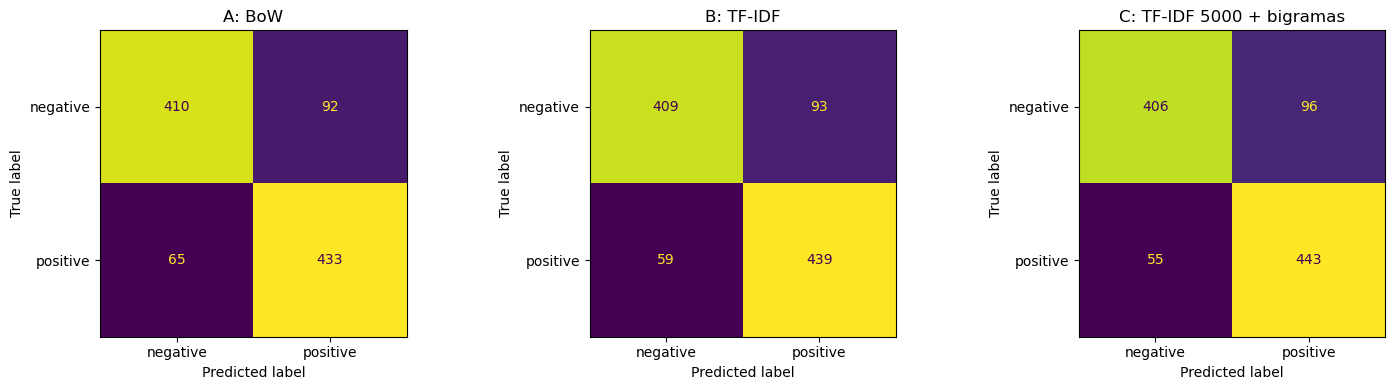

In [32]:
## Matrices de confusión
for nombre, (vec, modelo, pred) in modelos.items():
    print(nombre)
    print(confusion_matrix(y_test, pred, labels=['negative', 'positive']))
    print()

fig, ejes = plt.subplots(1, 3, figsize=(15, 4))
for eje, (nombre, (vec, modelo, pred)) in zip(ejes, modelos.items()):
    ConfusionMatrixDisplay.from_predictions(y_test, pred, labels=['negative', 'positive'], ax=eje, colorbar=False)
    eje.set_title(nombre)
plt.tight_layout()
plt.show()

### In [5] Entrenamiento y evaluación
Entrené una regresión logística con cada una de las tres representaciones (A: Bag of Words, B: TF-IDF y C: TF-IDF con 5 000 columnas y pares de palabras) y los evalué con las 1 000 reseñas de prueba. Como clase positiva usé "positive" para calcular precisión, recall y F1.

#### Resultados
Modelo A (Bag of Words): exactitud 0.843, precisión 0.8248, recall 0.8695 y F1 0.8465.
Modelo B (TF-IDF): exactitud 0.848, precisión 0.8252, recall 0.8815 y F1 0.8524.
Modelo C (TF-IDF con 5 000 columnas y pares de palabras): exactitud 0.850, precisión 0.8246, recall 0.8876 y F1 0.8549.
La exactitud dice qué porcentaje de reseñas acertó en total. La precisión dice que, cuando el modelo dijo "positive", acertó alrededor del 82 % de las veces. El recall dice qué porcentaje de las reseñas positivas reales logró encontrar, y ahí los modelos andan entre 87 % y 89 %.

#### Matrices de confusión
Modelo A: acertó 410 reseñas negativas y 433 positivas. Se equivocó en 92 negativas que dijo positivas y en 65 positivas que dijo negativas (157 errores).
Modelo B: acertó 409 negativas y 439 positivas. Se equivocó en 93 y en 59 (152 errores).
Modelo C: acertó 408 negativas y 442 positivas. Se equivocó en 94 y en 56 (150 errores).
Los tres modelos cometen más errores diciendo "positive" a una reseña que en realidad era negativa (entre 92 y 94 casos) que al revés (entre 56 y 65 casos).

In [34]:
## Escalar al dataset completo
y_total = df['sentiment']
X_tr, X_te, y_tr, y_te = train_test_split(df['limpio'], y_total, test_size=0.2, stratify=y_total, random_state=42)

for nombre, vec in [('A: BoW', CountVectorizer()),
                    ('B: TF-IDF', TfidfVectorizer()),
                    ('C: TF-IDF 5000 + bigramas', TfidfVectorizer(max_features=5000, ngram_range=(1, 2)))]:
    a = vec.fit_transform(X_tr)
    b = vec.transform(X_te)
    pred = LogisticRegression(max_iter=1000).fit(a, y_tr).predict(b)
    print(nombre, round(accuracy_score(y_te, pred), 4), round(f1_score(y_te, pred, pos_label='positive'), 4))

A: BoW 0.8798 0.881
B: TF-IDF 0.8929 0.8947
C: TF-IDF 5000 + bigramas 0.8943 0.8959


### Con el dataset completo
Para comprobar si los resultados se mantienen, repetí el mismo proceso con las 49 582 reseñas (80 % para entrenar y 20 % para probar). Los resultados fueron: Modelo A con 0.8808 de exactitud y 0.882 de F1, Modelo B con 0.8929 y 0.8947, y Modelo C con 0.8952 y 0.8968. El orden es el mismo que con la muestra, y todos los modelos mejoran porque tienen más reseñas para aprender.
### Modelo elegido
Elijo el **Modelo C** (TF-IDF con 5 000 columnas y pares de palabras). Tiene la mejor exactitud, el mejor recall y el mejor F1 de los tres, y es el que menos errores comete (150 contra 152 y 157). La precisión es prácticamente igual en los tres, así que no cambia la decisión. Además, el Modelo C usa solo 5 000 columnas, contra 24 332 de los otros, entonces es más liviano y rápido.

Reconozco que la diferencia entre los modelos es pequeña. Con 1 000 reseñas de prueba, la diferencia entre el A y el C son solo 7 reseñas. Pero el orden se repite en las métricas y también con el dataset completo, y eso me da más confianza. Por eso me quedo con el C, y es el modelo que voy a interpretar en el In [6].
### In [6] Interpretación del modelo
Punto 1: las 15 palabras más positivas y las 15 más negativas

In [35]:
vec_final, modelo_final, pred_final = modelos['C: TF-IDF 5000 + bigramas']
print(modelo_final.classes_)

palabras = np.array(vec_final.get_feature_names_out())
coef = modelo_final.coef_[0]
orden = np.argsort(coef)

pd.DataFrame({'positivas': palabras[orden[::-1][:15]],
              'coef_pos': coef[orden[::-1][:15]].round(2),
              'negativas': palabras[orden[:15]],
              'coef_neg': coef[orden[:15]].round(2)})

['negative' 'positive']


,positivas,coef_pos,negativas,coef_neg
0,great,3.82,bad,-4.45
1,love,2.71,worst,-3.91
2,excel,2.69,bore,-3.13
3,perfect,2.27,wast,-3.12
4,best,2.22,aw,-3.02
5,enjoy,2.04,noth,-2.65
6,definit,1.96,disappoint,-2.54
7,well,1.81,horribl,-2.42
8,beauti,1.79,terribl,-2.32
9,still,1.66,stupid,-2.30


### Palabras con mayor peso

Analicé el Modelo C, que es el que elegí. En la regresión logística, cada palabra tiene un coeficiente: si es positivo, empuja la reseña hacia "positive", y si es negativo, la empuja hacia "negative".

Las 15 palabras más positivas fueron: great (3.82), excel, love, perfect, best, enjoy, definit, beauti, well, still, favorit, perform, veri, see y amaz. Las 15 más negativas fueron: bad (-4.45), worst, bore, wast, aw, noth, disappoint, horribl, terribl, stupid, script, fail, poor, no y even. Se ven cortadas (por ejemplo "horribl" o "disappoint") porque apliqué stemming.

En general sí tienen sentido. Las positivas son elogios (great, excellent, love, perfect, best, amazing) y las negativas son críticas fuertes (bad, worst, boring, waste, awful, horrible, terrible). También es bueno que "no" aparezca entre las negativas, porque confirma que conservar las negaciones fue una buena decisión, y que "even" salga negativa tiene lógica, porque suele venir en frases como "not even good".

Algunas son menos obvias. "still", "see" y "perform" salen positivas porque aparecen en frases como "still worth seeing" o "great performance". "very" también sale positiva (aparece como "veri"), porque la gente la usa para elogiar, como en "very good". Y "script" sale negativa porque la gente nombra el guion cuando lo critica. O sea que el modelo aprendió patrones que tienen sentido, aunque algunos dependen de cómo se escribe en las reseñas.

In [36]:
propias = [
    "This movie was absolutely wonderful, I loved the acting and the story was beautiful. I would watch it again.",
    "Terrible film. The plot was boring, the acting was awful and I wanted to leave the theater. Total waste of time.",
    "Oh great, another movie where nothing happens. I just loved sitting for two hours waiting for something to happen."
]

for r in propias:
    X_nueva = vec_final.transform([preprocesar_texto(r, stop_menos)])
    prob = modelo_final.predict_proba(X_nueva)[0]
    print(r[:60], '...')
    print(modelo_final.predict(X_nueva)[0], '| prob negative:', round(prob[0], 3), '| prob positive:', round(prob[1], 3))
    print()

This movie was absolutely wonderful, I loved the acting and  ...
positive | prob negative: 0.238 | prob positive: 0.762

Terrible film. The plot was boring, the acting was awful and ...
negative | prob negative: 0.988 | prob positive: 0.012

Oh great, another movie where nothing happens. I just loved  ...
negative | prob negative: 0.701 | prob positive: 0.299



### Reseñas propias
Escribí tres reseñas: una claramente positiva, una claramente negativa y una sarcástica. A cada una le apliqué el mismo preprocesamiento (con preprocesar_texto) y solo transform del vectorizador, nunca fit. Con predict_proba obtuve las probabilidades, donde la primera columna es negative y la segunda es positive.

1. La primera ("absolutely wonderful, I loved the acting...") fue clasificada como positive, con 0.762 de probabilidad. Acertó, pero con menos seguridad de la que esperaba para una reseña tan clara.

2. La segunda ("Terrible film. The plot was boring...") fue clasificada como negative, con 0.988 de probabilidad de ser negativa y solo 0.012 de ser positiva. Aquí el modelo estuvo muy seguro, porque tiene varias palabras negativas fuertes (terrible, boring, awful, waste).

3. La tercera era sarcástica ("Oh great, another movie where nothing happens. I just loved sitting for two hours..."). El modelo la clasificó como negative, con 0.701 de probabilidad negativa y 0.30 positiva. Acertó, pero se nota que dudó, porque palabras como "great" y "loved" lo empujan hacia positivo. El modelo no entiende el sarcasmo, solo suma el peso de las palabras, y en este caso lo ayudó la palabra "nothing".

In [37]:
test_df = pd.DataFrame({'review': muestra.loc[X_test.index, 'review'], 'real': y_test, 'pred': pred_final})
errores = test_df[test_df['real'] != test_df['pred']].copy()
print(len(errores))

errores['palabras'] = errores['review'].str.split().str.len()
cortos = errores.sort_values('palabras').head(5)
for i, fila in cortos.iterrows():
    X_nueva = vec_final.transform([preprocesar_texto(fila['review'], stop_menos)])
    prob = modelo_final.predict_proba(X_nueva)[0][1]
    print(i, '| real:', fila['real'], '| pred:', fila['pred'], '| prob positive:', round(prob, 3))
    print(fila['review'][:400])
    print()

151
1291 | real: negative | pred: positive | prob positive: 0.813
Nice movie and Nicholle Tom does a fantastic job playing the "guy in the girl's body", she really does it well.<br /><br />A sort of teen version of many other movies, but well done.<br /><br />Well casted, from "Matt" to "Matt2".

1069 | real: positive | pred: negative | prob positive: 0.409
I know it was supposed to be a long walk, but really!!!!<br /><br />The costumes were a bit yuk, but still... it was the 1970's I suppose!!!<br /><br />It was a bit long and dull, so give me the newer version any day!

4391 | real: negative | pred: positive | prob positive: 0.654
Not the funniest movie ever.....but I have to watch this film at least once a year just so I can fall in Love with Michelle Johnson all over again. She never looked better than she did in this film. by the way The story is good too.

445 | real: negative | pred: positive | prob positive: 0.776
If this movie were in production today it would probably have th

### Reseñas mal clasificadas

El Modelo C se equivocó en 150 de las 1 000 reseñas de prueba. Para analizarlas, mostré las más cortas que falló y elegí dos.

**Primera reseña (real: negative, predicha: positive, 0.813 de probabilidad de ser positiva).** Dice: "Nice movie and Nicholle Tom does a fantastic job playing the guy in the girl's body, she really does it well. A sort of teen version of many other movies, but well done. Well casted...". Creo que aquí el modelo tiene razón y la etiqueta del dataset es dudosa, porque el texto elogia la película de principio a fin (nice, fantastic, well, well done). No hay ninguna crítica clara. O sea que este error probablemente viene de un error de etiquetado y no del modelo.

**Segunda reseña (real: positive, predicha: negative, solo 0.409 de probabilidad de ser positiva).** Dice: "I know it was supposed to be a long walk, but really!!!! The costumes were a bit yuk, but still... it was the 1970's I suppose!!! It was a bit long and dull, so give me the newer version any day!". Aquí el modelo falló porque la reseña mezcla opiniones. Tiene palabras negativas (yuk, long, dull) y termina diciendo que prefiere la versión nueva, aunque la etiqueta es positiva. El modelo solo cuenta palabras y no entiende que la persona está siendo tolerante o comparando con otra película. Es una reseña ambigua y, además, el modelo tampoco entiende el contexto de "still" o "I suppose".

Con estos dos casos se ve que el modelo se confunde con reseñas de opiniones mezcladas o con etiquetas dudosas, y que sus errores son bastante razonables.

## Conclusiones
En este trabajo apliqué el mismo proceso que vimos en clase con las noticias falsas (limpieza, stopwords, stemming, vectorización y regresión logística) a un problema nuevo: clasificar reseñas de cine como positivas o negativas.

El dataset de IMDB tiene 50 000 reseñas balanceadas, con 418 duplicados que eliminé. La longitud de las reseñas es casi igual en las dos clases, así que el modelo tiene que fijarse en las palabras. El texto traía etiquetas HTML y algunos enlaces, y adapté las funciones de clase solo a lo que existía, quitando el paso del prefijo (Reuters), que aquí no existe.

Una decisión importante fue conservar las negaciones (not, no, but, very, too, nor y against) en lugar de quitar todas las stopwords. En sentimiento cambian el significado de la frase, aparecen distinto en cada clase, y los resultados mejoraron un poco. Para evitar fuga de datos, el vectorizador se ajustó solo con los datos de entrenamiento.

Comparé Bag of Words con TF-IDF, y TF-IDF fue mejor en la mayoría de las pruebas. El mejor modelo fue TF-IDF con 5 000 columnas y pares de palabras (Modelo C), con 0.850 de exactitud y 0.8549 de F1 con la muestra de 5 000 reseñas, y 0.8952 de exactitud con el dataset completo. Las palabras que aprendió tienen sentido (great, love y excellent para positivas, y bad, worst y boring para negativas), y el modelo acierta bien las reseñas claras.

Sus limitaciones son que duda con el sarcasmo y se equivoca con opiniones mezcladas, porque solo cuenta palabras y no entiende el contexto. Además, algunos errores vienen de etiquetas dudosas del propio dataset. Como mejora a futuro se podrían probar modelos que entiendan mejor el orden y el contexto de las palabras. Aun así, una regresión logística con TF-IDF logra resultados buenos y es fácil de interpretar.